# From pixels to answer: ResNet-18 → PyNeuraLogic

One I-RAVEN puzzle, followed from its 16 raw panel images to a predicted answer, then a
quick accuracy check over a sample. Nothing here reads the XML labels on the way to the
answer; the XML is used only to show where perception was right or wrong.

| stage | what | from |
|---|---|---|
| perception | ResNet-18 turns each panel image into a 512-d vector, matched against a frozen codebook of 6622 attribute vectors | `log/universal_frontend_correct_proportional_mean3` (trained on RAVEN) |
| decoding | per position, the best-matching attribute combination; the object exists if its cosine > 0.23 | `pixel_pipeline.panels_from_preds` |
| encoding | objects laid into the 16 panels × 9 slots graph | `train_all_constellations.encode_puzzle` |
| reasoning | the trained PyNeuraLogic model scores the 8 candidates | `experiments/max_data_L2` (best checkpoint) |

Every step calls the project's own code, so this is exactly the pipeline behind the 63.96%
pixel result in `thesis/PYNEURALOGIC_NOTES.md` §11, run on CPU in one kernel.

**Which puzzles:** validation puzzles from index 300 on. Training never sees the validation
split, and checkpoint selection uses only its first 300 puzzles per constellation, so these
are unseen and do not touch the test split, which is kept for one final evaluation.

Run with the `pynl` kernel on a **compute node** (an interactive `srun` session, or the
batch command at the end), CPU only, about 2 minutes end to end. Not on the login node: it
kills CPU-heavy Jupyter kernels (SIGKILL). A bare 16-thread matrix-multiply kernel is killed
there, while the same work as a plain script is not.

In [1]:
import os, sys, glob, shutil, tempfile, time
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image, ImageDraw
from IPython.display import display

if os.path.basename(os.getcwd()) == "notebooks": os.chdir("..")   # paths below are relative to the repo root
ROOT = os.path.abspath(".")
for p in (ROOT, *(os.path.join(ROOT, d) for d in ("pynl", "torch_gnn", "frontend", "raven", "neuro-vector-symbolic-architectures"))):
    if p not in sys.path:
        sys.path.insert(0, p)

import neuralogic
neuralogic.set_max_memory_size(20)        # GB; an uncapped JVM can kill the kernel
from neuralogic.logging import clear_handlers
clear_handlers()                          # silence the Java engine's INFO/GC console log
torch.set_num_threads(16)

from gnn_solver import load_frontend                    # ResNet-18 frontend + codebook
from pixel_pipeline import (panels_from_preds, active_positions, key,
                            N_POS, N_PER_POS, N_ATTR, CONSTELLATIONS)
from train_all_constellations import encode_puzzle      # objects -> 144-slot graph inputs
from eval_pynl_test import load_model                   # PyNeuraLogic checkpoint loader
from train_pynl import parse                            # XML ground truth, for comparison only

FRONTEND = "log/universal_frontend_correct_proportional_mean3"
REASONER = "experiments/max_data_L2"
PREDS    = "experiments/frontend_preds/universal_frontend_correct_proportional_mean3_val.npz"
TAU = 0.23                                 # the frontend's own detection threshold
SPLIT, SKIP = "val", 300                   # unseen puzzles (see above)

# attribute vocabularies, checked against rendered panels
TYPES = ["triangle", "square", "pentagon", "hexagon", "circle"]
GREYS = [255, 224, 196, 168, 140, 112, 84, 56, 28, 0]

def describe(o):
    return f"{TYPES[o['type']]:<8}  size {o['size']}/5  grey {GREYS[o['color']]:>3}  at position {o['pos']}"

def puzzle_files(cfg):
    return sorted(glob.glob(f"data/I-RAVEN-10000/{cfg}/*_{SPLIT}.npz"))[SKIP:]

print("torch", torch.__version__, "| JAVA_HOME", os.environ.get("JAVA_HOME", "<unset>"))

torch 2.14.0+cpu | JAVA_HOME /mnt/appl/software/Java/21.0.8


/home/kassyask/.conda/envs/pynl/lib/python3.11/site-packages/neuralogic/core/builder/builder.py:4: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from tqdm.autonotebook import tqdm


## 1. The puzzle, as pixels

A puzzle is 16 grayscale images of 160×160: eight context panels forming a 3×3 matrix with
the last cell missing, and eight candidate answers.

data/I-RAVEN-10000/distribute_four/RAVEN_1270_val.npz   constellation distribute_four   correct answer: candidate 3


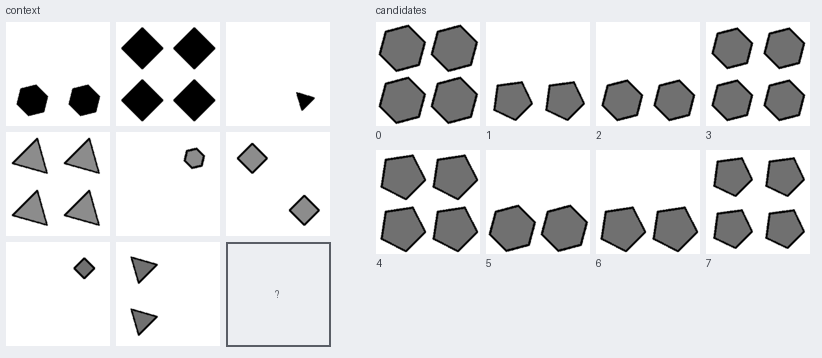

In [2]:
def show_puzzle(images, marks=None, s=104, gap=6):
    # 3x3 context (missing cell shown as '?') next to the 8 candidates; marks = {candidate: (rgb, label)}
    marks = marks or {}
    W, H = 3 * s + 4 * gap + 40 + 4 * s + 5 * gap, max(3 * s + 4 * gap, 2 * (s + 18) + 3 * gap) + 22
    canvas = Image.new("RGB", (W, H), (236, 238, 242))
    d = ImageDraw.Draw(canvas)
    d.text((gap, 4), "context", fill=(60, 64, 72))
    for p in range(9):
        x, y = gap + (p % 3) * (s + gap), 22 + (p // 3) * (s + gap)
        if p < 8:
            canvas.paste(Image.fromarray(images[p]).resize((s, s)).convert("RGB"), (x, y))
        else:
            d.rectangle([x, y, x + s, y + s], outline=(90, 94, 102), width=2)
            d.text((x + s // 2 - 3, y + s // 2 - 6), "?", fill=(90, 94, 102))
    x0 = 3 * s + 4 * gap + 40
    d.text((x0, 4), "candidates", fill=(60, 64, 72))
    for c in range(8):
        x, y = x0 + (c % 4) * (s + gap), 22 + (c // 4) * (s + 18 + gap)
        canvas.paste(Image.fromarray(images[8 + c]).resize((s, s)).convert("RGB"), (x, y))
        rgb, label = marks.get(c, ((60, 64, 72), ""))
        if c in marks:
            d.rectangle([x - 3, y - 3, x + s + 2, y + s + 2], outline=rgb, width=4)
        d.text((x, y + s + 3), f"{c} {label}", fill=rgb)
    display(canvas)

CFG, IDX = "distribute_four", 0
f = puzzle_files(CFG)[IDX]
npz = np.load(f)
images, target = npz["image"], int(npz["target"])
print(f"{os.path.relpath(f)}   constellation {CFG}   correct answer: candidate {target}")
show_puzzle(images)

## 2. Perception: what the ResNet sees

Each panel goes through ResNet-18 to a 512-d vector, which is compared by cosine similarity
with every row of the frozen codebook: 22 positions × (300 attribute combinations + 1
"object here" row). For each position the constellation can use, the best of its 300
attribute rows is the candidate object; it exists if that cosine clears 0.23.

In [3]:
frontend, cos_layer, _, _ = load_frontend(FRONTEND, device="cpu")
W = F.normalize(cos_layer.W.data)

def perceive(images):
    x = torch.tensor(images, dtype=torch.float).unsqueeze(1)          # (16, 1, 160, 160)
    with torch.no_grad():
        sims = F.linear(F.normalize(frontend(x)), W).view(16, N_POS, N_PER_POS)
    best, idx = sims[..., :N_ATTR].max(-1)                             # (16, 22) each
    return best.numpy(), idx.numpy()

t0 = time.time()
maxcos, argidx = perceive(images)
print(f"16 panels perceived in {time.time() - t0:.2f}s on CPU")

pos = active_positions(CFG)
print(f"\ncontext panel 0, the {len(pos)} positions {CFG} can use:")
print(f"{'position':>9} {'best cosine':>12} {'object?':>8}   best match")
for q in pos:
    o = panels_from_preds(maxcos, argidx, [q], -1.0)[0][0]            # decode regardless of threshold
    print(f"{q:>9} {maxcos[0, q]:>12.3f} {'yes' if maxcos[0, q] > TAU else 'no':>8}   "
          f"{describe(o) if maxcos[0, q] > TAU else '(below threshold, ignored)'}")

Load pretrained model from ImageNet1k


Loaded frontend: d=512, W=torch.Size([6622, 512]), epoch=198, acc=95.2625%


16 panels perceived in 0.74s on CPU

context panel 0, the 4 positions distribute_four can use:
 position  best cosine  object?   best match
        1        0.126       no   (below threshold, ignored)
        2        0.147       no   (below threshold, ignored)
        3        0.468      yes   hexagon   size 2/5  grey   0  at position 3
        4        0.462      yes   hexagon   size 2/5  grey   0  at position 4


In [4]:
pixel_panels = panels_from_preds(maxcos, argidx, pos, TAU)
truth = parse(f.replace(".npz", ".xml"), CFG)            # used only to grade perception

ok = [key(pixel_panels[p]) == key(truth[p]) for p in range(16)]
print(f"panels perceived exactly right: {sum(ok)}/16\n")
for p in range(16):
    name = f"context {p}" if p < 8 else f"candidate {p - 8}"
    print(f"{name:<12} {'✓' if ok[p] else '✗'}  " + " | ".join(describe(o) for o in pixel_panels[p]))
    if not ok[p]:
        print(f"{'':<12}    truth: " + " | ".join(describe(o) for o in truth[p]))

panels perceived exactly right: 16/16

context 0    ✓  hexagon   size 2/5  grey   0  at position 3 | hexagon   size 2/5  grey   0  at position 4
context 1    ✓  square    size 4/5  grey   0  at position 1 | square    size 4/5  grey   0  at position 2 | square    size 4/5  grey   0  at position 3 | square    size 4/5  grey   0  at position 4
context 2    ✓  triangle  size 0/5  grey   0  at position 4
context 3    ✓  triangle  size 4/5  grey 140  at position 1 | triangle  size 4/5  grey 140  at position 2 | triangle  size 4/5  grey 140  at position 3 | triangle  size 4/5  grey 140  at position 4
context 4    ✓  hexagon   size 0/5  grey 140  at position 2
context 5    ✓  square    size 2/5  grey 140  at position 1 | square    size 2/5  grey 140  at position 4
context 6    ✓  square    size 0/5  grey 112  at position 2
context 7    ✓  triangle  size 2/5  grey 112  at position 1 | triangle  size 2/5  grey 112  at position 3
candidate 0  ✓  hexagon   size 5/5  grey 112  at position 1 | hexag

**Check against the GPU pipeline.** The full-split run (`pixel_pipeline.py perceive`, on an
A100) cached its detections for every validation puzzle. Decoding them must give exactly the
objects decoded here on CPU.

In [5]:
cache = np.load(PREDS)
row = int(np.where(cache["files"] == os.path.relpath(f, ROOT))[0][0])
gpu_panels = panels_from_preds(cache["maxcos"][row], cache["argidx"][row], pos, TAU)
same = sum(key(a) == key(b) for a, b in zip(pixel_panels, gpu_panels))
print(f"decoded panels identical to the GPU pipeline: {same}/16")
assert same == 16

decoded panels identical to the GPU pipeline: 16/16


## 3. Into the graph

The perceived objects are laid into the same structure the model was trained on: 16 panels ×
9 slots = 144 nodes, slot *k* being the *k*-th position this constellation can use. Empty
slots get a learned pad embedding.

In [6]:
attrs, active = encode_puzzle(pixel_panels, CFG)
print("attrs ", tuple(attrs.shape), "  columns: position, colour, type, size, panel")
print("active", tuple(active.shape), f"  {int(active.sum())} objects, {int((~active).sum())} empty slots")

attrs  (144, 5)   columns: position, colour, type, size, panel
active (144,)   41 objects, 103 empty slots


## 4. Reasoning: PyNeuraLogic scores the candidates

The checkpoint is copied aside first, because a training job may be writing to that
directory. Its template does the message passing and the scoring; torch supplies only the
attribute embeddings.

In [7]:
tmp = tempfile.mkdtemp()
for n in ("model_best.pt", "template_best.bin"):
    shutil.copy(os.path.join(REASONER, n), tmp)
model, ck, args = load_model(tmp)
print(f"reasoner: {REASONER}, epoch {ck['epoch']}, val {100 * ck['val_acc']:.2f}%")

with torch.no_grad():
    logits = model(attrs, active)
prob = torch.softmax(logits, 0)
pred = int(logits.argmax())

print(f"\n{'candidate':>10} {'score':>9} {'prob':>7}")
for c in torch.argsort(prob, descending=True).tolist():
    tag = ("  <- predicted and correct" if c == pred == target else
           "  <- predicted" if c == pred else "  <- correct" if c == target else "")
    print(f"{c:>10} {float(logits[c]):>9.3f} {100 * float(prob[c]):>6.1f}%{tag}")

with torch.no_grad():
    pred_xml = int(model(*encode_puzzle(truth, CFG)).argmax())
print(f"\nfrom pixels: candidate {pred}   from XML labels: candidate {pred_xml}   correct: {target}")
print("this puzzle is answered correctly" if pred == target else
      f"this puzzle is answered wrongly; {CFG} is one of the model's weakest constellations "
      f"(the layout changes between panels). Change IDX in section 1 to look at others.")

reasoner: experiments/max_data_L2, epoch 78, val 68.52%



 candidate     score    prob
         1  -159.629   20.8%  <- predicted
         7  -159.689   19.6%
         2  -159.932   15.4%
         6  -159.932   15.4%
         3  -159.952   15.1%  <- correct
         5  -160.573    8.1%
         4  -161.316    3.8%
         0  -161.997    1.9%

from pixels: candidate 1   from XML labels: candidate 1   correct: 3
this puzzle is answered wrongly; distribute_four is one of the model's weakest constellations (the layout changes between panels). Change IDX in section 1 to look at others.


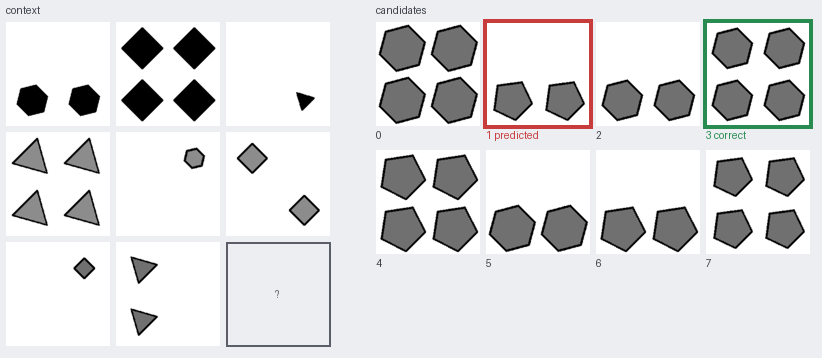

In [8]:
marks = {target: ((40, 140, 80), "correct")}
if pred != target:
    marks[pred] = ((200, 60, 60), "predicted")
else:
    marks[target] = ((40, 140, 80), "predicted, correct")
show_puzzle(images, marks)

## 5. Accuracy from pixels on a sample

The same five steps over unseen validation puzzles from every constellation, scoring each
puzzle from pixels and, for comparison, from the XML labels. The loop also re-checks every
puzzle's decoded objects against the GPU pipeline's cache.

In [9]:
N = 20                                       # puzzles per constellation
rows, mismatched_cache = [], 0
t0 = time.time()
for cfg in CONSTELLATIONS:
    cpos = active_positions(cfg)
    hit_pix = hit_xml = seen = n = 0
    for fp in puzzle_files(cfg)[:N]:
        z = np.load(fp)
        mc, ai = perceive(z["image"])
        pix = panels_from_preds(mc, ai, cpos, TAU)
        tru = parse(fp.replace(".npz", ".xml"), cfg)
        r = int(np.where(cache["files"] == os.path.relpath(fp, ROOT))[0][0])
        gpu = panels_from_preds(cache["maxcos"][r], cache["argidx"][r], cpos, TAU)
        mismatched_cache += sum(key(a) != key(b) for a, b in zip(pix, gpu))
        y = int(z["target"])
        with torch.no_grad():
            hit_pix += int(model(*encode_puzzle(pix, cfg)).argmax()) == y
            hit_xml += int(model(*encode_puzzle(tru, cfg)).argmax()) == y
        seen += all(key(a) == key(b) for a, b in zip(pix, tru))
        n += 1
    rows.append((cfg, n, seen, hit_pix, hit_xml))

print(f"{len(CONSTELLATIONS) * N} puzzles in {time.time() - t0:.0f}s\n")
print(f"{'constellation':<40} {'n':>4} {'all 16 seen':>12} {'from pixels':>12} {'from XML':>9}")
tot = [0, 0, 0, 0]
for cfg, n, seen, hp, hx in rows:
    print(f"{cfg:<40} {n:>4} {100 * seen / n:>11.0f}% {100 * hp / n:>11.0f}% {100 * hx / n:>8.0f}%")
    tot = [a + b for a, b in zip(tot, (n, seen, hp, hx))]
n, seen, hp, hx = tot
print("-" * 80)
print(f"{'OVERALL':<40} {n:>4} {100 * seen / n:>11.1f}% {100 * hp / n:>11.1f}% {100 * hx / n:>8.1f}%")
print(f"\npanels whose decoded objects differ from the GPU pipeline: {mismatched_cache}")
assert mismatched_cache == 0

140 puzzles in 146s

constellation                               n  all 16 seen  from pixels  from XML
center_single                              20         100%          85%       85%
distribute_four                            20         100%          40%       40%
distribute_nine                            20          85%          35%       35%
left_center_single_right_center_single     20         100%          95%       95%
up_center_single_down_center_single        20         100%          80%       80%
in_center_single_out_center_single         20         100%         100%      100%
in_distribute_four_out_center_single       20          70%          60%       60%
--------------------------------------------------------------------------------
OVERALL                                   140        93.6%        70.7%     70.7%

panels whose decoded objects differ from the GPU pipeline: 0


## What this shows

* Raw images in, answer out, with the trained ResNet-18 and the trained PyNeuraLogic model in
  one CPU kernel. Perception is near-perfect on most constellations; the misses are small
  objects in `distribute_nine` and `in_distribute_four_out_center_single`.
* Pixel accuracy tracks XML accuracy closely: when all 16 panels are perceived correctly, the
  model's input is identical to the XML version, so the answer is too.
* The sample is small (20 per constellation), so its percentages move a lot between runs of
  different puzzles. For the full-split numbers use `pixel_pipeline.py`
  (`thesis/PYNEURALOGIC_NOTES.md` §11): 63.96% from pixels vs 64.00% from XML on the test
  split, at epoch 62.

**Caveats** (§11.4): the constellation label comes from the dataset folder, as in the XML
pipeline; the frontend was trained on RAVEN, which shares some images with I-RAVEN, inflating
perception by under a point where it matters; and the reasoner checkpoint is the live run's
current best, so its epoch and scores change as training continues.

To re-execute this notebook in a batch job (writes the outputs in place):

```bash
sbatch --partition=amdfast --cpus-per-task=16 --mem=32G --time=0:30:00 --wrap \
  "source /mnt/appl/software/Anaconda3/2024.02-1/etc/profile.d/conda.sh && conda activate pynl && \
   export PYTHONNOUSERSITE=1 JAVA_HOME=/mnt/appl/software/Java/21.0.8 && \
   jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.kernel_name=python3 \
   pixels_to_answer.ipynb"
```